In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Find the project folder
if Path("results/model_comparison_results.csv").exists():
    project_path = Path(".")
elif Path("../results/model_comparison_results.csv").exists():
    project_path = Path("..")
else:
    raise FileNotFoundError(
        "Results CSV not found. Check that the notebook is "
        "inside the notebooks folder and the results folder exists."
    )

results_path = project_path / "results"

# Load the saved experiment results
results = pd.read_csv(
    results_path / "model_comparison_results.csv"
)

display(results)

,Experiment,Model,Split,Precision,Recall,F1-score,PR-AUC,ROC-AUC
0,LR-RANDOM-01,Logistic Regression,Random,0.0238,0.9598,0.0464,0.5817,0.9908
1,LR-TEMPORAL-01,Logistic Regression,Temporal,0.1102,0.8828,0.1959,0.6801,0.9880
2,RF-RANDOM-01,Random Forest,Random,0.0983,0.9897,0.1789,0.9193,0.9994
3,RF-TEMPORAL-01,Random Forest,Temporal,0.2796,0.9547,0.4325,0.8995,0.9991
4,XGB-RANDOM-01,XGBoost,Random,0.9730,0.8125,0.8856,0.9544,0.9997
5,XGB-TEMPORAL-01,XGBoost,Temporal,0.9997,0.7158,0.8343,0.9570,0.9998


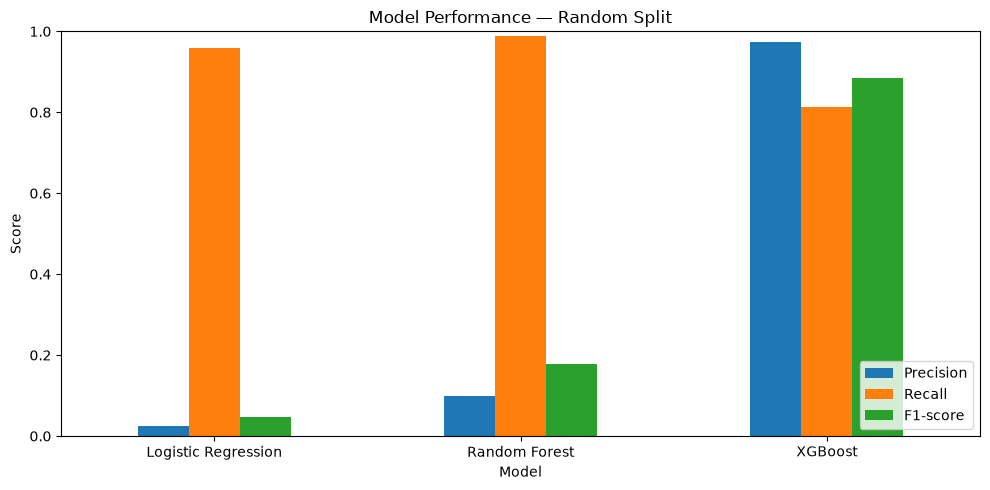

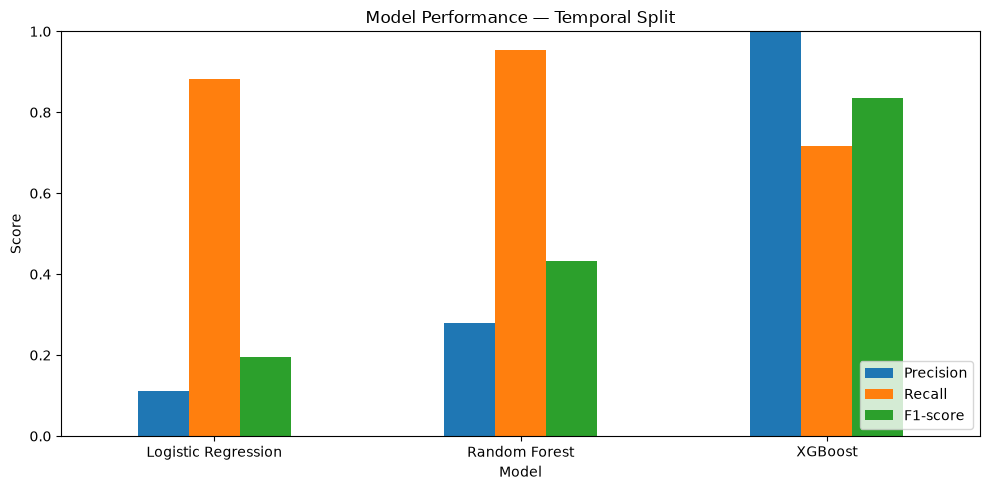

In [3]:
# Compare Precision, Recall and F1-score
metrics = ["Precision", "Recall", "F1-score"]

for split_name in ["Random", "Temporal"]:
    split_results = results[results["Split"] == split_name]

    ax = split_results.set_index("Model")[metrics].plot(
        kind="bar",
        figsize=(10, 5),
        ylim=(0, 1),
        rot=0
    )

    ax.set_title(f"Model Performance — {split_name} Split")
    ax.set_ylabel("Score")
    ax.set_xlabel("Model")
    ax.legend(loc="lower right")
    plt.tight_layout()
    plt.show()

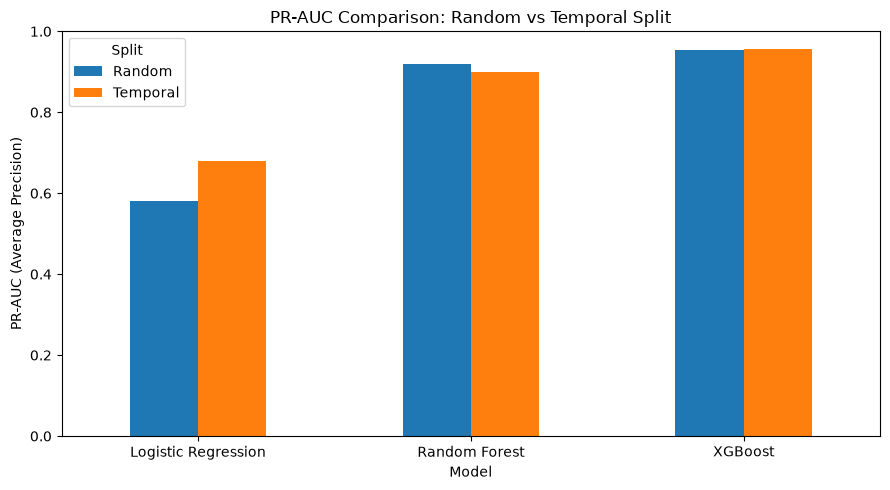

In [4]:
# Compare PR-AUC across models and splits

pr_auc_comparison = results.pivot(
    index="Model",
    columns="Split",
    values="PR-AUC"
)

ax = pr_auc_comparison.plot(
    kind="bar",
    figsize=(9, 5),
    ylim=(0, 1),
    rot=0
)

ax.set_title("PR-AUC Comparison: Random vs Temporal Split")
ax.set_ylabel("PR-AUC (Average Precision)")
ax.set_xlabel("Model")
ax.legend(title="Split")
plt.tight_layout()
plt.show()

## Results Interpretation and Discussion

### 1. Performance on the Random Split

Among the evaluated traditional machine learning models, XGBoost achieved the highest F1-score (0.8856) and precision (0.9730) on the random test split. Its recall was 0.8125, indicating that some fraudulent transactions were not detected. Random Forest achieved a recall of 0.9897 but a much lower precision of 0.0983, showing a trade-off between detecting fraud and generating false alarms. Logistic Regression also achieved high recall (0.9598), but its precision was low (0.0238).

### 2. Performance on the Temporal Split

On the temporal split, Random Forest achieved a recall of 0.9547 and an F1-score of 0.4325. XGBoost achieved a precision of 0.9997 and a recall of 0.7158, resulting in an F1-score of 0.8343. These results show that the models behave differently depending on the evaluation period and the selected classification threshold.

### 3. Class Imbalance and Evaluation Metrics

Fraudulent transactions represent approximately 0.129% of the complete dataset. Consequently, accuracy alone would not adequately describe model performance. Precision, recall, F1-score and Precision–Recall AUC are important for understanding the balance between detecting fraudulent transactions and limiting false positives.

### 4. Temporal Generalization

The fraud prevalence in the temporal training period was approximately 0.078%, compared with approximately 0.329% in the test period. This difference indicates a change in the target distribution across time. The temporal results should therefore be interpreted separately from the random-split results. The observed difference does not, by itself, establish the cause of the distribution shift.

### 5. Limitations and Next Steps

The dataset is synthetic PaySim financial transaction data rather than real UPI transaction records. The results may not directly generalize to real-world UPI systems. Further experiments will compare traditional machine learning models with GCN, GraphSAGE and GAT under carefully defined evaluation protocols. Explainability and temporal generalization will also be investigated. Comparisons should use consistent test periods, clearly documented graph construction rules and appropriate metrics.